# IMAGO Hackathon | Air temperature

**Dataset:** IMAGO air temperature indicators derived from Met Office HadUK-Grid (1 km), aggregated to MSOA-equivalent areas. Published annual files cover **2015–2024**. This starter uses **2024** only.

**Available formats:** CSV (table) and GeoPackage (table + boundaries). Data for this example are stored in `data/air_temperature/`.

## 1. Find and load the data

This notebook is placed in `IMAGO Hackathon/notebooks/`, alongside the `data/` folder. We use the MSOA **GeoPackage** so that boundaries are available for mapping.

In [1]:
from pathlib import Path
import geopandas as gpd

data_dir = Path("../data/air_temperature")
files = sorted(data_dir.glob("*MSOA*2024*.gpkg"))
if not files:
    raise FileNotFoundError(f"No 2024 MSOA GeoPackage found in {data_dir.resolve()}. Check the filename and folder.")

print("Loading:", files[0].name)
temp = gpd.read_file(files[0])
temp.head()

Loading: temperature_indicators_MSOA_2024_GeoPackage.gpkg


,dt_zn_c,dt_zn_n,annual_mean_tmp,annual_max_tmp,annual_min_tmp,winter_mean_tmp,spring_mean_tmp,summer_mean_tmp,autumn_mean_tmp,summer_max_tmp,winter_min_tmp,temporal_sd_tmp,tmp_anomaly_absolute,tmp_anomaly_relative,extreme_hot_days_mean,hot_spell_3day_mean,geometry
0,E02000001,City of London 001,12.763455,16.280210,9.247190,7.962327,12.237062,18.246445,12.783379,23.006287,5.307874,4.218369,2.558206,3.939247,3.0,7.00000,"MULTIPOLYGON (((532135.138 182198.131, 532158...."
1,E02000002,Barking and Dagenham 001,12.076904,15.995796,8.215314,7.301272,11.551524,17.542759,12.085314,22.753950,4.413336,4.201226,2.472255,4.046119,3.0,7.00000,"MULTIPOLYGON (((548881.563 190845.265, 548881...."
2,E02000003,Barking and Dagenham 002,12.203361,16.079384,8.376277,7.425026,11.671482,17.684784,12.206841,22.834980,4.557454,4.209268,2.478608,4.044049,3.0,7.00871,"MULTIPOLYGON (((549102.438 189324.625, 548954...."
3,E02000004,Barking and Dagenham 003,12.338967,16.196173,8.529167,7.562093,11.781488,17.846867,12.342216,22.967804,4.709777,4.221317,2.477158,4.074961,3.0,8.00000,"MULTIPOLYGON (((551550.056 187364.705, 551478 ..."
4,E02000005,Barking and Dagenham 004,12.341122,16.168375,8.552910,7.556808,11.802893,17.843620,12.337282,22.924101,4.712059,4.220945,2.483515,4.043092,3.0,7.67559,"MULTIPOLYGON (((549099.634 187656.076, 549161...."


## 2. Explore the available indicators

Inspect the fields and choose an indicator of interest.

In [2]:
print("Areas:", len(temp))
print("CRS:", temp.crs)
print("Columns:", temp.columns.tolist())

indicator = "summer_max_tmp"
if indicator in temp.columns:
    display(temp[[indicator]].describe())
else:
    print(f"{indicator} is not present. Choose a column from the list above.")

Areas: 9448
CRS: EPSG:27700
Columns: ['dt_zn_c', 'dt_zn_n', 'annual_mean_tmp', 'annual_max_tmp', 'annual_min_tmp', 'winter_mean_tmp', 'spring_mean_tmp', 'summer_mean_tmp', 'autumn_mean_tmp', 'summer_max_tmp', 'winter_min_tmp', 'temporal_sd_tmp', 'tmp_anomaly_absolute', 'tmp_anomaly_relative', 'extreme_hot_days_mean', 'hot_spell_3day_mean', 'geometry']


,summer_max_tmp
count,9448.000000
mean,20.225898
std,1.798089
min,13.648763
25%,18.627092
50%,20.458002
75%,21.715382
max,23.160931


## 3. Quick map

An example visualisation using the 2024 summer maximum air-temperature indicator (°C).

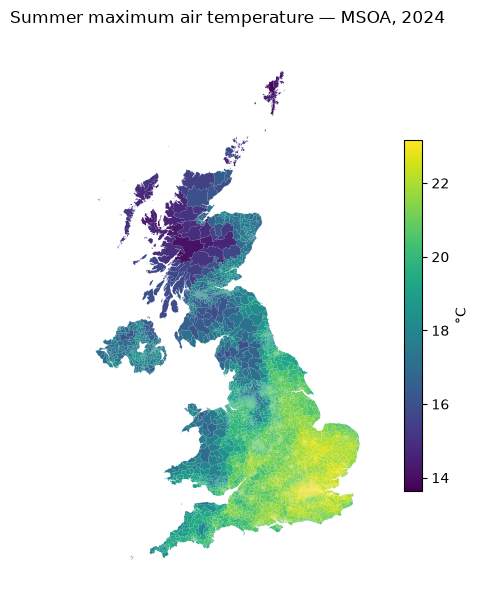

In [3]:
if indicator in temp.columns:
    ax = temp.plot(column=indicator, legend=True, figsize=(8, 7), linewidth=0,
                   legend_kwds={"label": "°C", "shrink": 0.65})
    ax.set_title("Summer maximum air temperature — MSOA, 2024")
    ax.set_axis_off()

**Try next:** Change the indicator or load another year (2015–2024) when its file is available. This notebook is only a starting point; explore your own questions during the hackathon.